# Stacked Maps

The following notebook provides a walkthrough on how to both use unspotable in jupyter and also create new stellar surface maps from the original unspotable basis set.

**NOTE:** to run this code, quad-limb-70i-units must already exist in the eridani-outputs folder.

## Library and Data Setup

### Core Imports

In [1]:
#General imports
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from cmcrameri import cm
import faulthandler
faulthandler.enable()

# Directory structure - this is required for running jupyter in a folder
from pathlib import Path
maindir = str(Path(os.getcwd()).parent)
libdir  = os.path.join(maindir, 'lib')
if not libdir in sys.path:
    sys.path.append(maindir)
    sys.path.append(libdir)

# lib imports
from lib import eigen
from lib import utils
from lib import fitclass as fc
from lib.spotable import spotable as se

# import starry2 and set basic configuration
import starry2 as starry
starry.config.quiet = True
starry.config.lazy = True
sys.setrecursionlimit(10000) # starry seems to have a lot of recursion

### Importing each .py file

In [2]:
import create_eigens
import create_emaps
import create_rv
import create_real_null

### Reading Config File

In [3]:
fit = fc.Fit()
fit.read_config("../eridani.cfg")

cfg = fit.cfg

lmax = cfg.sim.lmax
udeg = cfg.star.udeg

# setting up units if present in cfg
if fit.cfg.star.units:
    scaler = 5.670374419e-8 * fit.cfg.star.teff**4
    power = int(np.floor(np.log10(scaler)))
    if power > 6:
        units = f"x10$^{power}$ W m$^{{-2}}$"
    else:
        units = f"W m$^{{-2}}$"
else:
    scaler = 1
    units = None

### Python magic commands for better notebook displays

In [4]:
%matplotlib inline

### Reading in data from quad-limb-70i-units

In [66]:
scaled_eigeny = np.loadtxt("../eridani-outputs/quad-limb-70i-units/stored-scaled-null-eigens/scaled-null-eigeny.txt")

scaled_amps = np.loadtxt("../eridani-outputs/quad-limb-70i-units/stored-scaled-null-eigens/scaled-null-amps.txt")

In [6]:
print(f"Shape: {scaled_eigeny.shape} - {scaled_eigeny.shape[0]} maps with {scaled_eigeny.shape[1]} coefficients")
print(f"Shape: {scaled_amps.shape} - {scaled_amps.shape[0]} maps with {scaled_amps.shape[1]} coefficients (limb ratio & amp)")

Shape: (25, 36) - 25 maps with 36 coefficients
Shape: (25, 2) - 25 maps with 2 coefficients (limb ratio & amp)


## Creating a Star

Let's make a star and modify it a bit

In [7]:
# call initstar using parameters from config file - make sure include_rv = True!
star = utils.initstar(fit, lmax, udeg=udeg, include_rv=True)

To look at the star's flux, you can call it from starry directly:

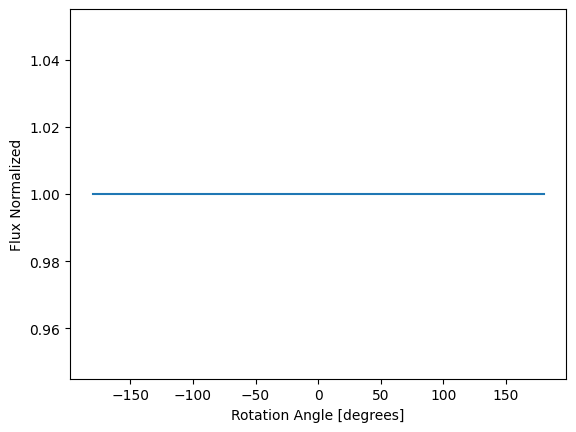

In [8]:
#Let's take a look at the star's flux
theta = np.linspace(-180,180,361)

flux = star.map.flux(theta=theta).eval()

plt.plot(theta,flux)
plt.xlabel("Rotation Angle [degrees]")
plt.ylabel("Flux Normalized")
plt.show()


Or you can call one of the unspotable function!

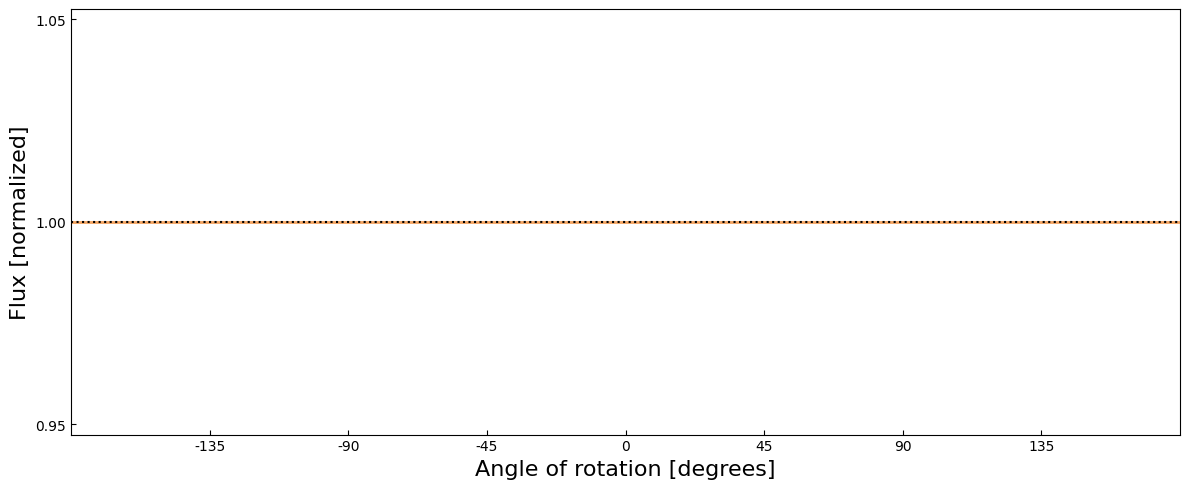

In [9]:
# this has some extra functionality you can play with.  If you are curious see create_rv.py!
create_rv.flux_rv_line(star,theta = theta, flux_only=True)

And we can look at the RV

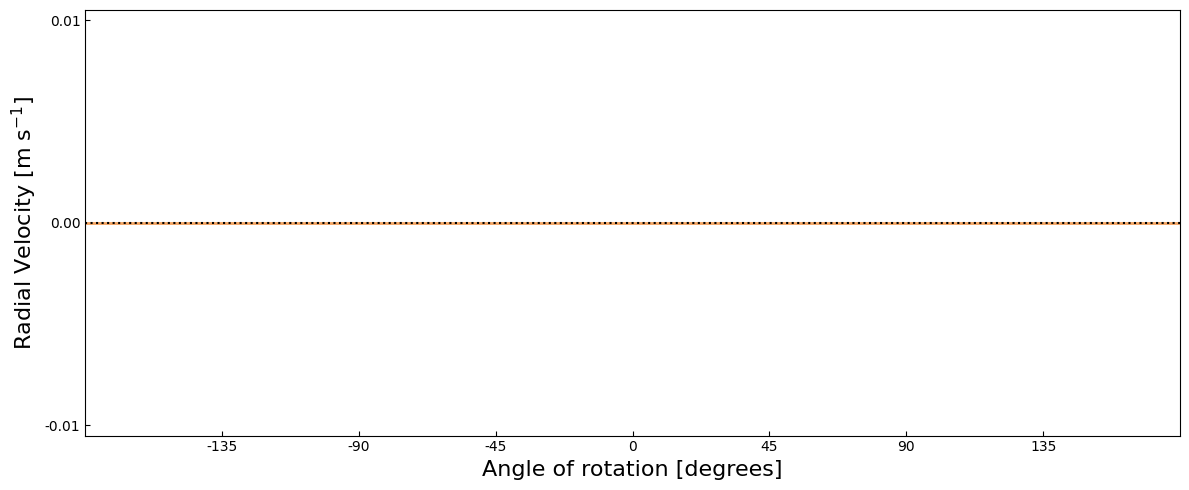

In [10]:
create_rv.flux_rv_line(star,theta = theta, rv_only=True)

Okay, now we can set the star to have some coefficients from our eigenamps

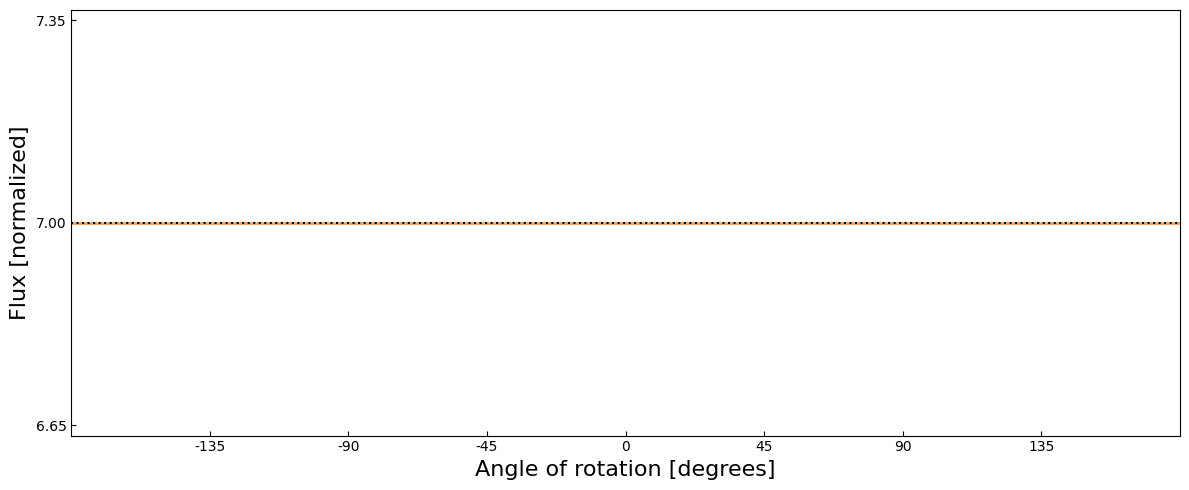

In [11]:
star.map[:,:] = scaled_eigeny[16]

create_rv.flux_rv_line(star,theta = theta, flux_only=True)

As expected for a null space map, the light curve is still zero.  But let's look at the RV

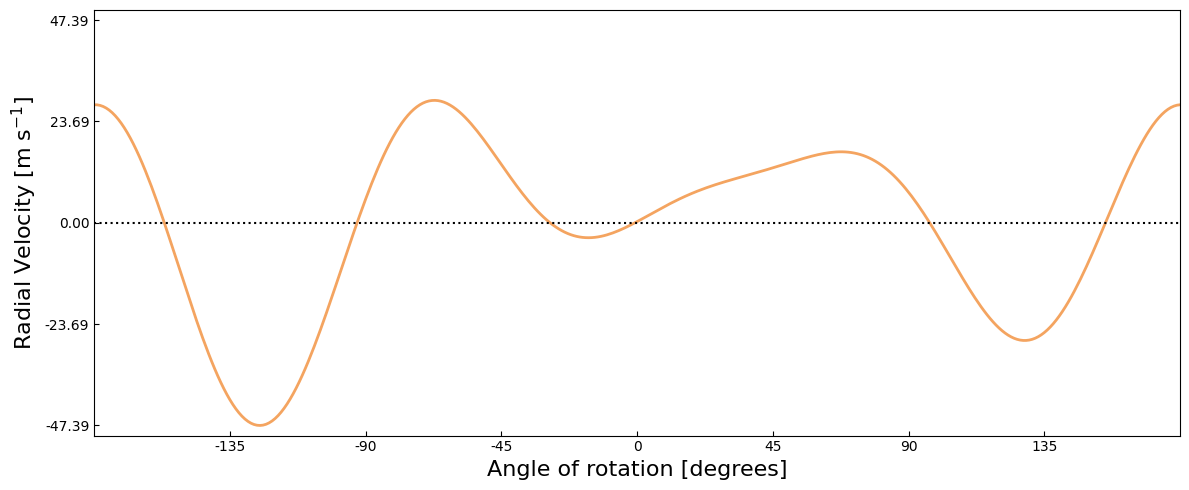

In [12]:
create_rv.flux_rv_line(star,theta = theta, rv_only=True)

And now we have some RV!  If we want to get really fancy we can animate it:

In [13]:
create_rv.map_animations(star, html5_video=True, dpi=100, interval=50)

You'll notice that the flux is set to 7 which is pretty arbitrary.  Let's apply some units to this map

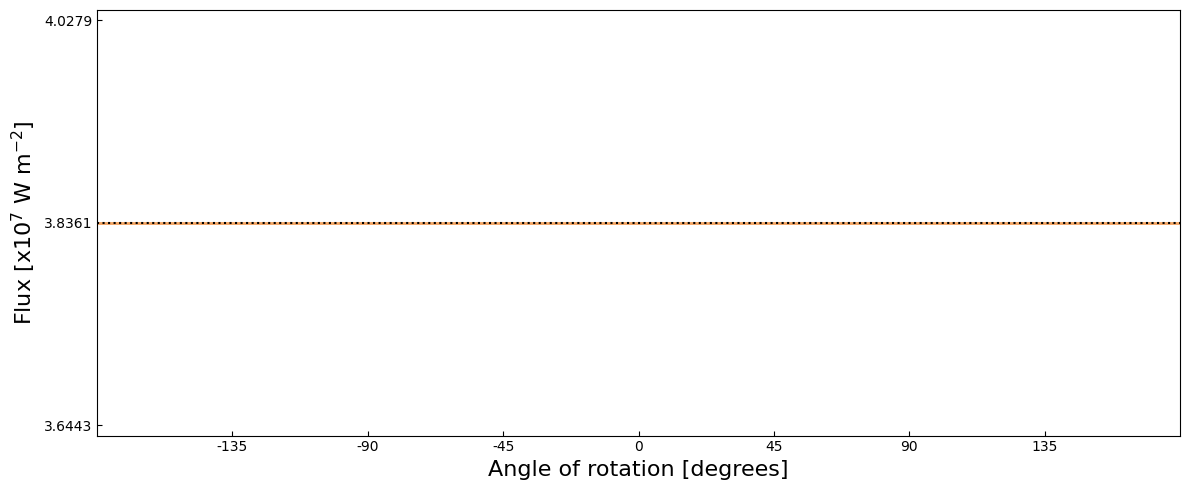

In [14]:
#Here we scale the map to have the expected surface flux values in W m^-2
ratio, amp = scaled_amps[16]

star.map.amp = amp

create_rv.flux_rv_line(star,theta = theta, flux_only=True, units=units)

create_rv.map_animations(star, html5_video=True, dpi=100, interval=50, units=units)

## Stacking multiple maps on one star

It is quite simply to create a map that contains multiple null space patterns in this code.  Let's make a star to do this with:

In [15]:
stacked_star = utils.initstar(fit, lmax, udeg=udeg, include_rv=True)

As before, we can set it to have null map at index 16 but also add null map at index 3.

Let's make individuals for each of these too to compare!

In [16]:
stacked_star.map[:,:] = scaled_eigeny[16]

stacked_star.map[:,:] += scaled_eigeny[3]

In [17]:
star16 = utils.initstar(fit, lmax, udeg=udeg, include_rv=True)

star16.map[:,:] = scaled_eigeny[16]

star3 = utils.initstar(fit, lmax, udeg=udeg, include_rv=True)

star3.map[:,:] = scaled_eigeny[3]

Time to compare some lightcurves and RVs

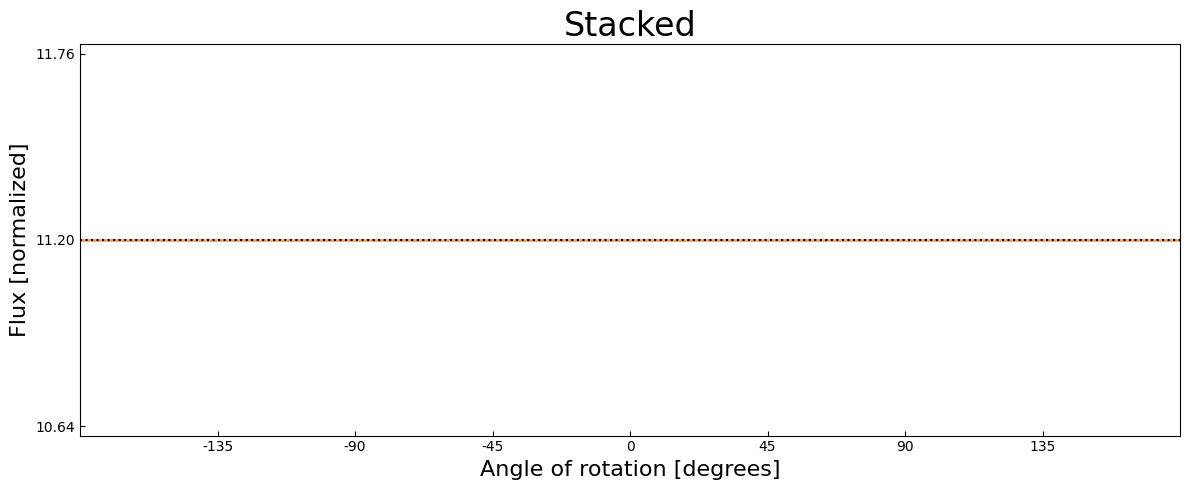

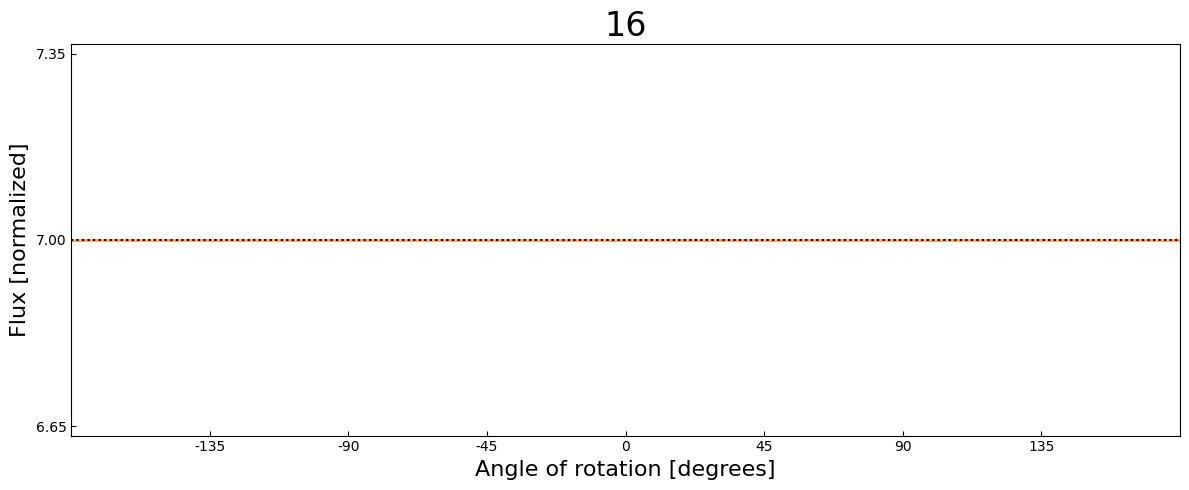

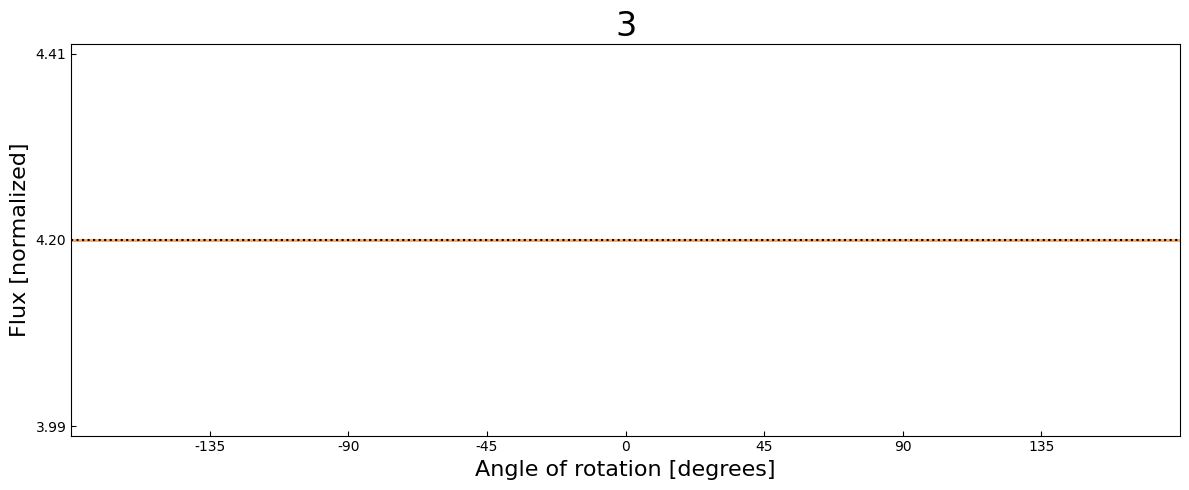

In [18]:
create_rv.flux_rv_line(stacked_star,theta = theta, flux_only=True,title="Stacked")
create_rv.flux_rv_line(star16,theta = theta, flux_only=True,title="16")
create_rv.flux_rv_line(star3,theta = theta, flux_only=True,title="3")

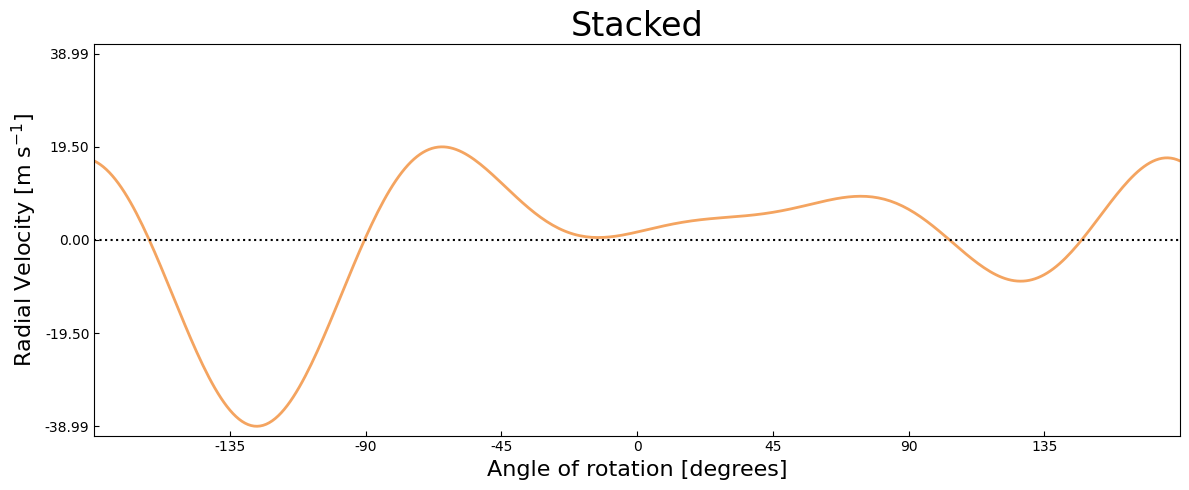

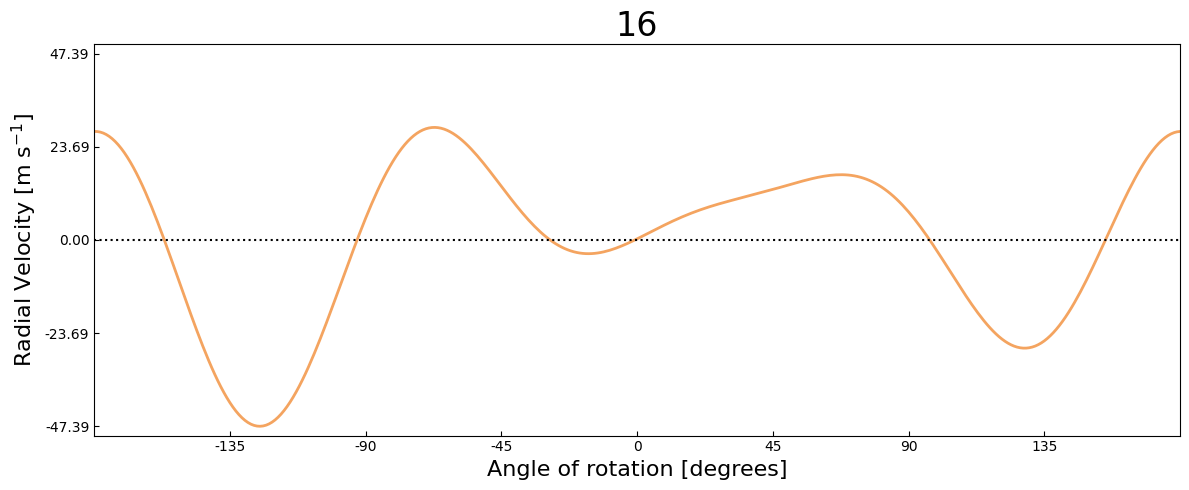

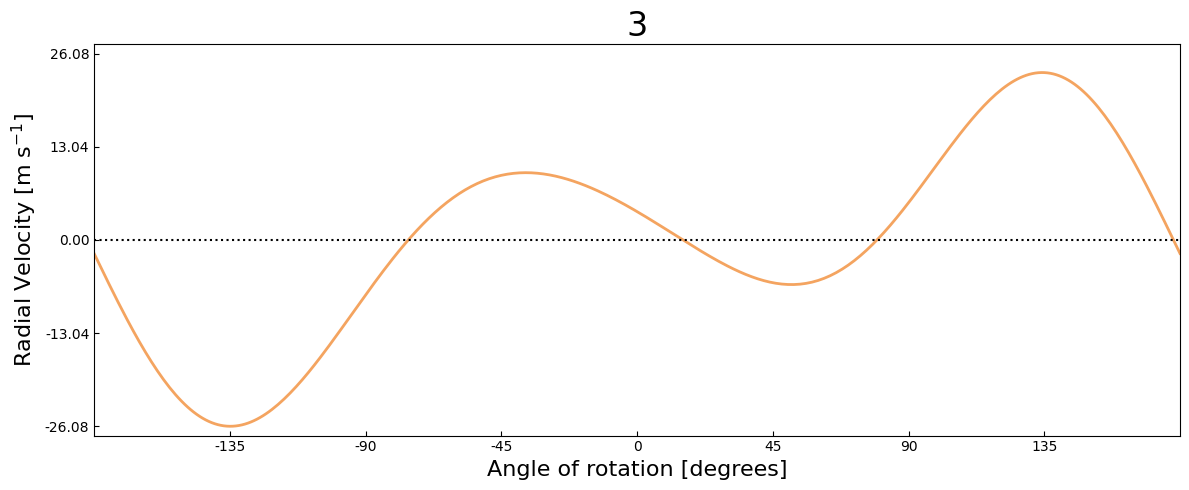

In [19]:
create_rv.flux_rv_line(stacked_star,theta = theta, rv_only=True,title="Stacked")
create_rv.flux_rv_line(star16,theta = theta, rv_only=True,title="16")
create_rv.flux_rv_line(star3,theta = theta, rv_only=True,title="3")

It is pretty clear that these values are stacking! 

Now it is important we check that the flux range remains reasonable after doing this

In [92]:
uni_star = utils.initstar(fit, lmax, udeg=udeg, include_rv=True)

uni_star.map.amp = ratio

In [93]:
# stacked_star.map.amp /= ratio
# star16.map.amp /= ratio
# star3.map.amp /= ratio

stacked_surface = stacked_star.map.render(projection="rect",rv=False).eval()
star16_surface = star16.map.render(projection="rect",rv=False).eval()
star3_surface = star3.map.render(projection="rect",rv=False).eval()

#NOTE I can omit the limb ratio here because these all have the same limb and we only want relative scales 
# (but I'll add it to be safe)

# stacked_star.map.amp *= ratio
# star16.map.amp *= ratio
# star3.map.amp *= ratio

#also note the ratio is the same for each map because they all have the same limb applied

In [94]:
uni_star.map[0,0] = np.max(star16.map.flux(theta=theta).eval())

uni_value = np.max(uni_star.map.intensity(lat=0, lon=np.linspace(-90,90,181),rv=False).eval())

amount_below_uni = uni_value - star16.map.minimize()[-1].eval()
amount_above_uni = np.max(star16_surface) - uni_value

ratio_below = (uni_value - amount_below_uni) / uni_value
ratio_above = (amount_above_uni + uni_value) / uni_value

print(ratio_below,ratio_above)

0.6824349357020076 1.4042298022108917


In [95]:
print(amount_above_uni)

0.9007075658250652


In [96]:
scaled_eigeny[16]

array([ 7.01122152e+00,  0.00000000e+00, -1.74142331e-03, -7.93339083e-03,
        2.38166065e-02,  2.49850860e-02, -3.24609288e-03, -2.17310934e-02,
       -3.02495213e-02, -1.79665890e-02,  1.15681470e-01, -1.37115639e-01,
        2.25059987e-02, -2.60254479e-02,  7.06071168e-03,  4.81103483e-01,
        4.87662614e-01,  1.09090268e-01, -1.41666856e-01,  1.68497524e-01,
        7.13364391e-03,  1.46074599e-01, -1.56720610e-01, -1.94633824e-01,
       -5.07176914e-02, -7.03442031e-02,  1.82772887e-01,  8.92506455e-02,
       -4.15070487e-01, -2.44817401e-01,  2.60002141e-02,  1.04798034e-01,
        1.03870314e-02,  2.30733894e-01, -5.63098722e-02,  2.91422216e-02])

In [97]:
norm_eigeny = np.loadtxt("../eridani-outputs/quad-limb-70i-units/stored-norm-null-eigens/norm_null_eigeny.txt")

realistic_star, inv_realistic_star, uni_star_limb, uni_star, ratio_no_limb = create_real_null.set_up_stars(fit, norm_eigeny[16], uni_comp=7)


In [98]:
realistic_star.map[:,:].eval()

array([ 7.01122152e+00,  0.00000000e+00, -1.74142331e-03, -7.93339083e-03,
        2.38166065e-02,  2.49850860e-02, -3.24609288e-03, -2.17310934e-02,
       -3.02495213e-02, -1.79665890e-02,  1.15681470e-01, -1.37115639e-01,
        2.25059987e-02, -2.60254479e-02,  7.06071168e-03,  4.81103483e-01,
        4.87662614e-01,  1.09090268e-01, -1.41666856e-01,  1.68497524e-01,
        7.13364391e-03,  1.46074599e-01, -1.56720610e-01, -1.94633824e-01,
       -5.07176914e-02, -7.03442031e-02,  1.82772887e-01,  8.92506455e-02,
       -4.15070487e-01, -2.44817401e-01,  2.60002141e-02,  1.04798034e-01,
        1.03870314e-02,  2.30733894e-01, -5.63098722e-02,  2.91422216e-02])

In [103]:
print(uni_value - star16.map.minimize(ntries=20, oversample=2)[-1].eval())
print(uni_value - realistic_star.map.minimize(ntries=20, oversample=2)[-1].eval())
print(np.max(inv_realistic_star.map.render(projection="rect",rv=False).eval()) - uni_value)

0.7076006135386517
0.707600613538653
0.7074451683619212


In [102]:
print(np.max(star16_surface) - uni_value)
print(uni_value - inv_realistic_star.map.minimize(ntries=20, oversample=2)[-1].eval())
print(np.max(realistic_star.map.render(projection="rect",rv=False).eval()) - uni_value)

0.9007075658250652
0.9008186822689459
0.9007075658250638


In [86]:
2.9885807347437567 / uni_value

1.3412493079150853

In [87]:
1.5206061166401992 / uni_value

0.6824349357020071

Now this is only a rough estimate because render is not a perfect projection.  It would be better to use minimize, but that takes more steps to complete and we only need an estimate right now

In [36]:
print(f"The upper ratio for each of stacked, 16, 3:")
stars = [stacked_star, star16, star3]
surfaces = [stacked_surface, star16_surface, star3_surface]

for i in range(3):
    star_i = stars[i]
    surface_i = surfaces[i]
    uni_star.map[0,0] = np.max(star_i.map.flux(theta=theta).eval())

    # uni_value = np.max(uni_star.map.intensity(lat=0, lon=np.linspace(-90,90,181),rv=False).eval())

    uni_star.map.amp /= ratio
    uni_render = uni_star.map.render(projection="rect",rv=False).eval()
    uni_star.map.amp *= ratio

    # print(uni_value,np.max(uni_render),np.min(uni_render))

    upper_ratio = np.max(surface_i) / np.max(uni_render)
    lower_ratio = star_i.map.minimize()[-1].eval() / np.max(uni_render)
    other_lower = np.min(surface_i) / np.max(uni_render)

    # print(star_i.map.minimize()[-1].eval())
    # print(np.min(surface_i))

    # upper_ratio = np.max(surface_i) / np.max(uni_value)
    # lower_ratio = np.min(surface_i) / np.max(uni_value)

    print(f"Upper - {upper_ratio} & Lower - {lower_ratio} & Other Lower - {other_lower}")


The upper ratio for each of stacked, 16, 3:
Upper - 1.326214877186921 & Lower - 0.5901767956465028 & Other Lower - 0.6997022394246766
Upper - 1.4042534522910164 & Lower - 0.5608552954814092 & Other Lower - 0.6824825088640325
Upper - 1.334496490012706 & Lower - 0.3680961630216922 & Other Lower - 0.3794933797731064


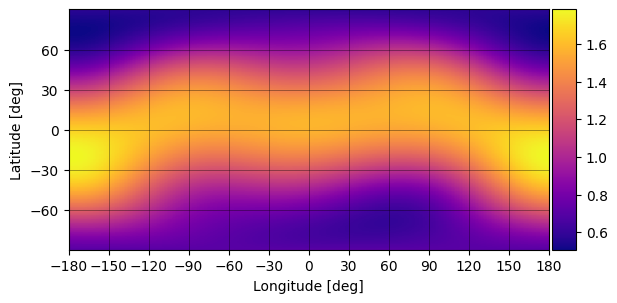

In [34]:
star3.map.show(rv=False,projection="rect",colorbar=True)

In [22]:
print(uni_render)

[[1.6267363 1.6267363 1.6267363 ... 1.6267363 1.6267363 1.6267363]
 [1.6267363 1.6267363 1.6267363 ... 1.6267363 1.6267363 1.6267363]
 [1.6267363 1.6267363 1.6267363 ... 1.6267363 1.6267363 1.6267363]
 ...
 [1.6267363 1.6267363 1.6267363 ... 1.6267363 1.6267363 1.6267363]
 [1.6267363 1.6267363 1.6267363 ... 1.6267363 1.6267363 1.6267363]
 [1.6267363 1.6267363 1.6267363 ... 1.6267363 1.6267363 1.6267363]]


In [23]:
np.max(uni_star.map.render(projection="rect",rv=False).eval())

1.336901521971923